# Demo of for Fruits-And-Vegetables-Detection-Dataset

#### Model Training and Fine Tuning

- Note that this will take very long on a local machine. 
- Our baseline models have been trained on the [Ultralytics HUB](http://ultralytics.com/hub) in the cloud  
- The HUB also proves an Inference API for our Models. Check it [here](https://hub.ultralytics.com/projects/AIhZh0lIAJko7snRmM5f)

In [ ]:
from ultralytics import YOLO

# Load a pretrained model (e.g. YOLOv8)
model = YOLO('yolov8n.yaml')  # build a new model from YAML

# Fine tuning the model on our custom dataset
results = model.train(data='LVIS_Fruits_And_Vegetables/data.yaml', epochs=50, imgsz=640)

#### Inference with Baseline Models

In [1]:
# if zipped unzip weights.zip
import zipfile
import os

zip_file_path = 'Model_Weights/weights.zip'

extract_dir = 'Model_Weights'

# Create the extraction directory if it doesn't exist
if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

# Unzip the file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print(f'Files extracted to {extract_dir}')

Files extracted to Model_Weights


In [2]:
from ultralytics import YOLO
import os

# Load a model
model = YOLO('Model_Weights/yolo_fruits_and_vegetables_v2.pt')  # pretrained YOLOv8n model

image_dir = "LVIS_Fruits_And_Vegetables/images/test"
images = [os.path.join(image_dir, img) for img in os.listdir(image_dir)]

num_images = 20

# Set confidence and iou threshold
conf = 0.6
iou = 0.1
show_results = False

# Run batched inference on a list of images
results = model(images[:num_images], conf=conf, iou=iou)  # return a list of Results objects

if show_results:
    for result in results:
        result.show()


0: 640x640 5 carrots, 2 lettuces, 1 strawberry, 1856.2ms
1: 640x640 5 broccolis, 10 carrots, 1 cauliflower, 1 pea/pea food, 1856.2ms
2: 640x640 1 asparagus, 16 blackberrys, 14 blueberrys, 1 green bean, 1856.2ms
3: 640x640 1 edible corn/corn/maize, 55 lemons, 3 orange/orange fruits, 1856.2ms
4: 640x640 (no detections), 1856.2ms
5: 640x640 (no detections), 1856.2ms
6: 640x640 1 apple, 1856.2ms
7: 640x640 (no detections), 1856.2ms
8: 640x640 2 orange/orange fruits, 1856.2ms
9: 640x640 1 banana, 1856.2ms
10: 640x640 2 orange/orange fruits, 1856.2ms
11: 640x640 2 orange/orange fruits, 1856.2ms
12: 640x640 (no detections), 1856.2ms
13: 640x640 (no detections), 1856.2ms
14: 640x640 1 broccoli, 4 carrots, 1 cucumber/cuke, 1856.2ms
15: 640x640 1 banana, 1856.2ms
16: 640x640 1 avocado, 2 pickles, 2 tomatos, 1856.2ms
17: 640x640 2 carrots, 1 lettuce, 6 tomatos, 1856.2ms
18: 640x640 20 blueberrys, 1856.2ms
19: 640x640 2 strawberrys, 1856.2ms
Speed: 3.8ms preprocess, 1856.2ms inference, 82.3ms pos

In [3]:
# create a directory to save the results
if not os.path.exists('Example_Results'):
    os.makedirs('Example_Results')

# Save results and show detections
for result in results:
    result.show()
    #save locally
    result.save(filename=f'Example_Results/{os.path.basename(result.path)}.png')

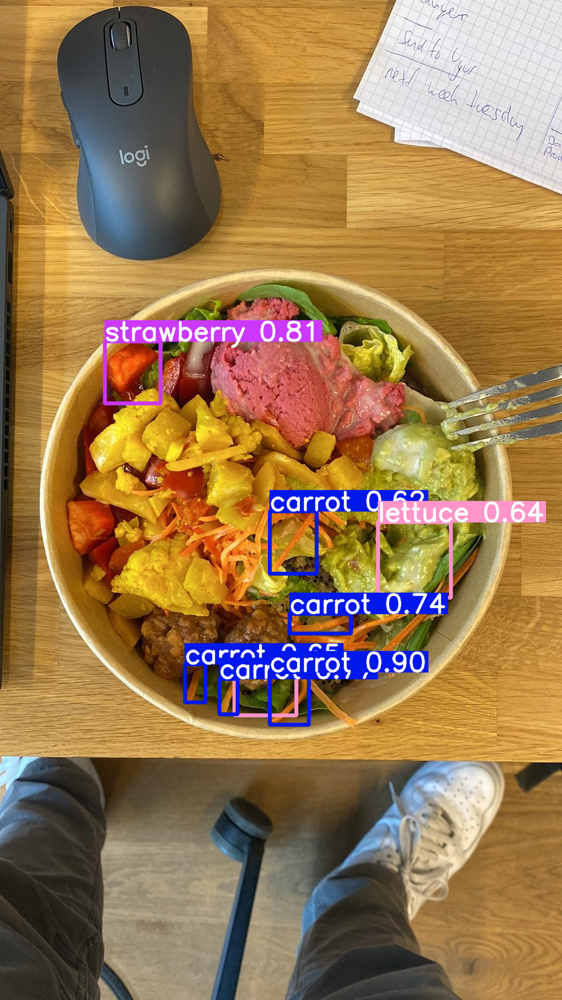

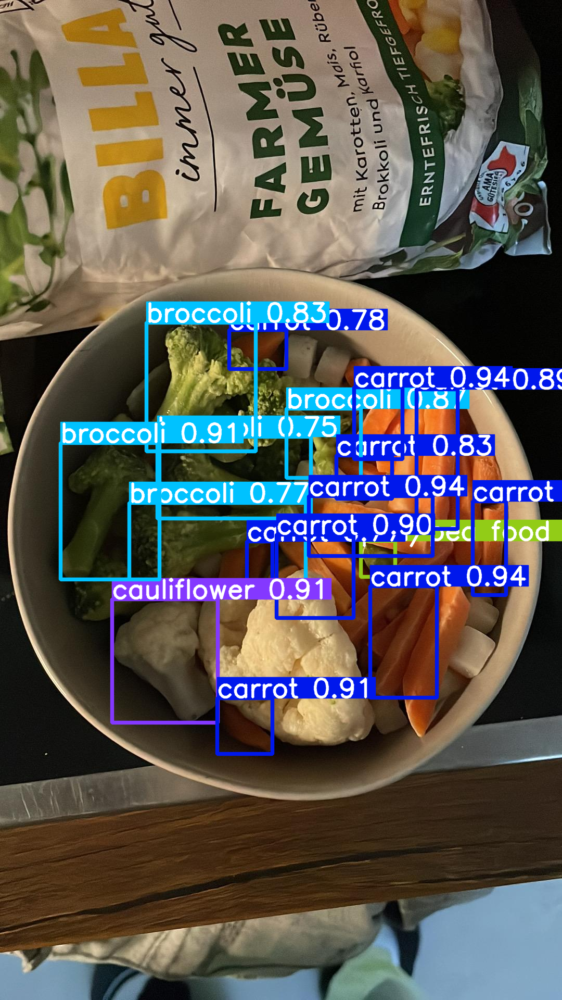

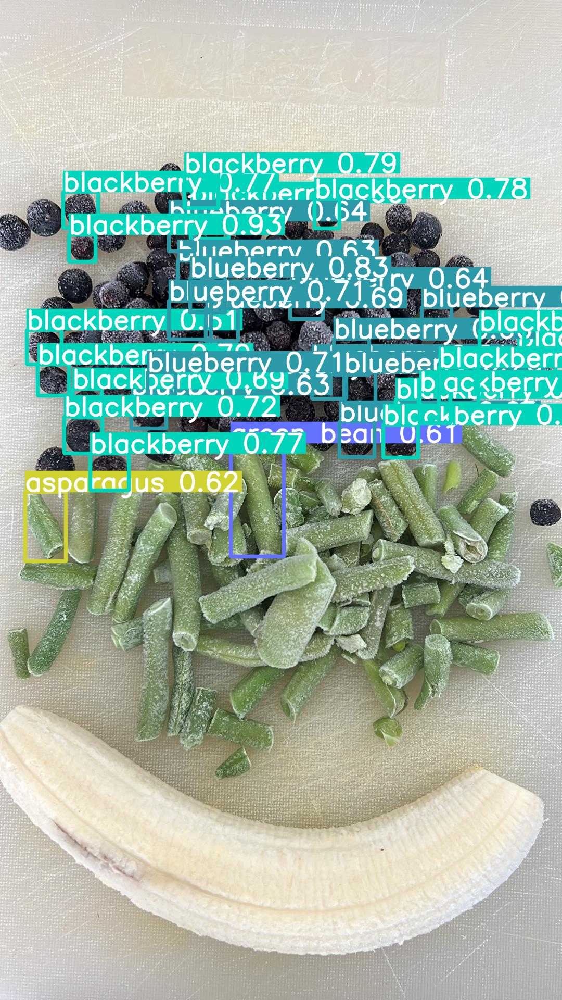

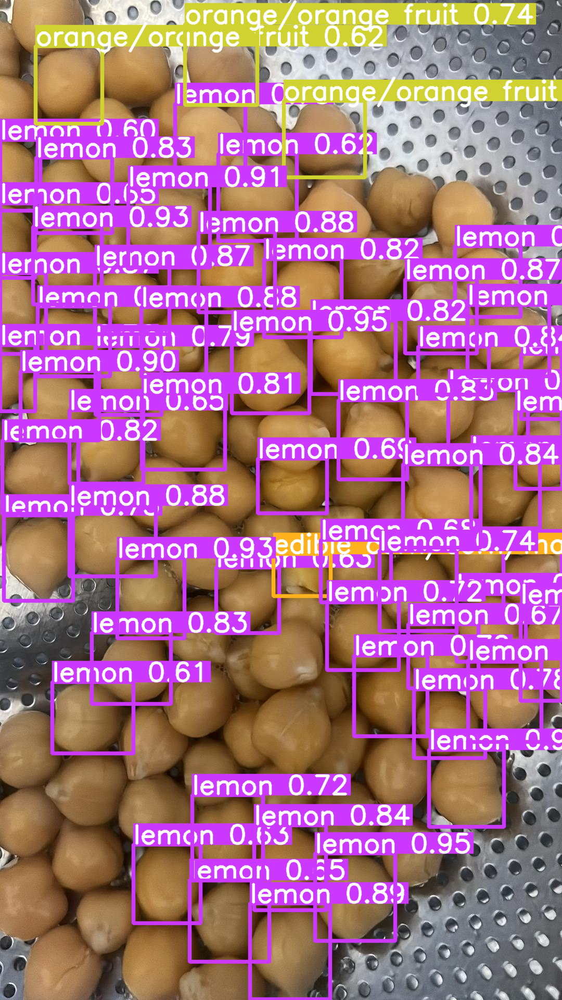

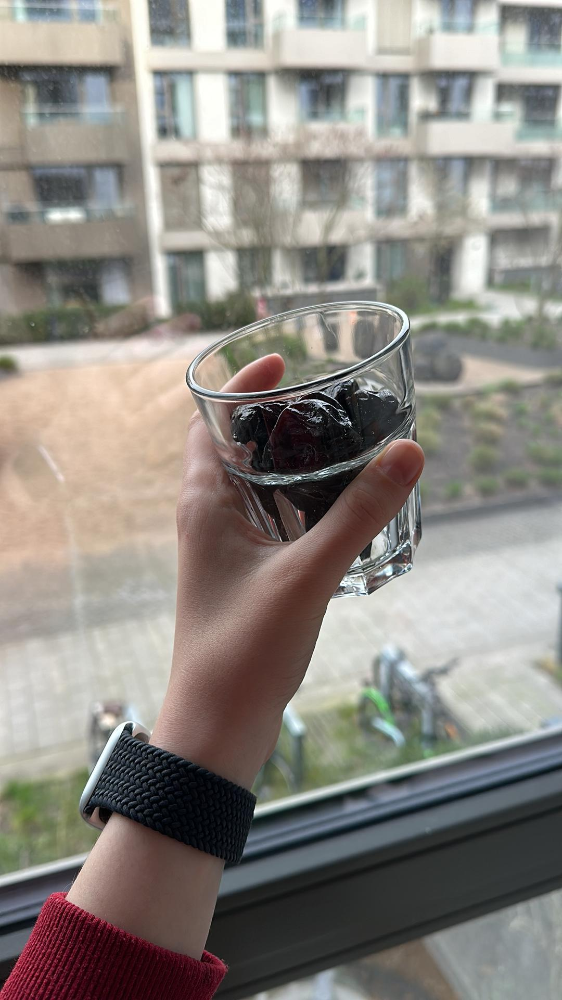

...

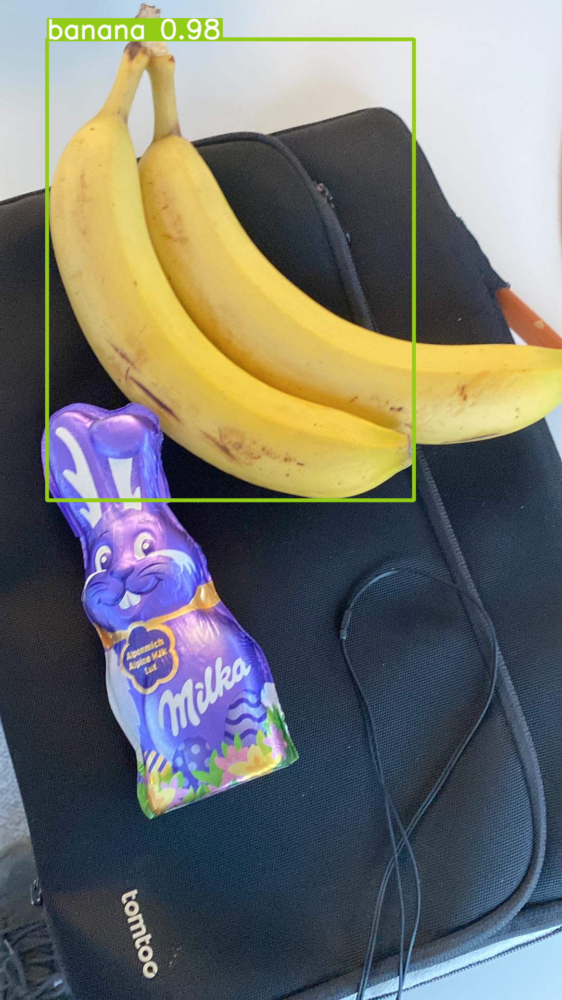

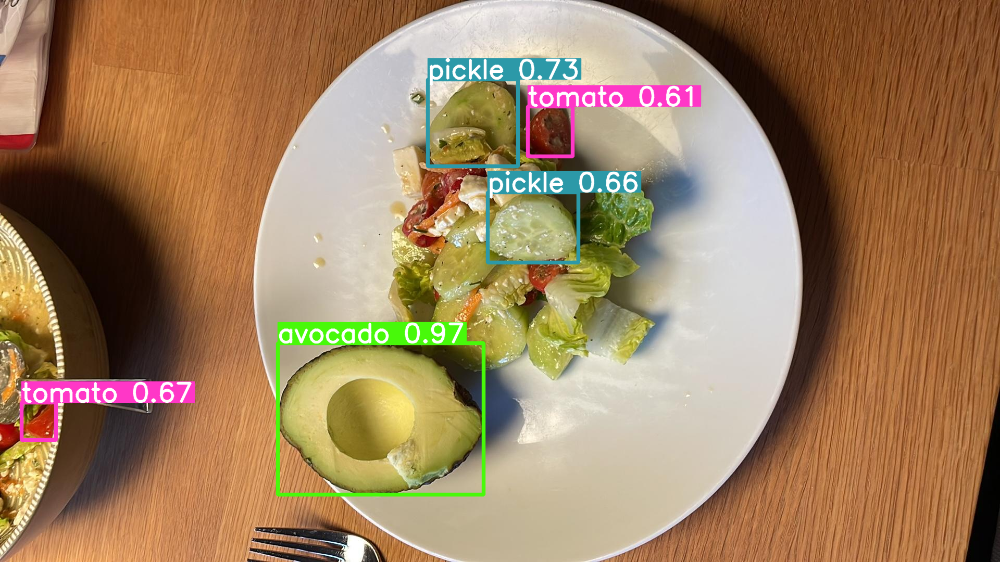

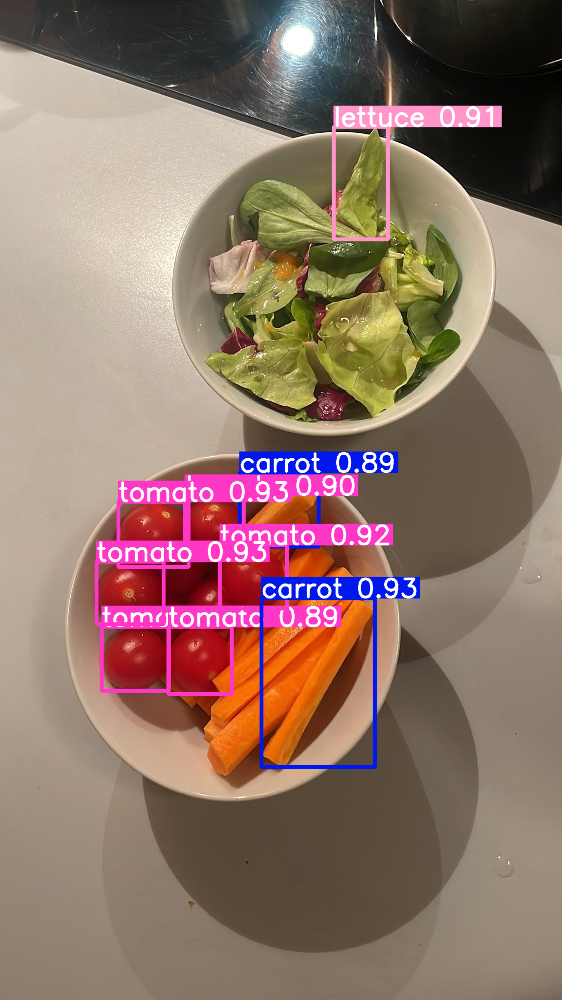

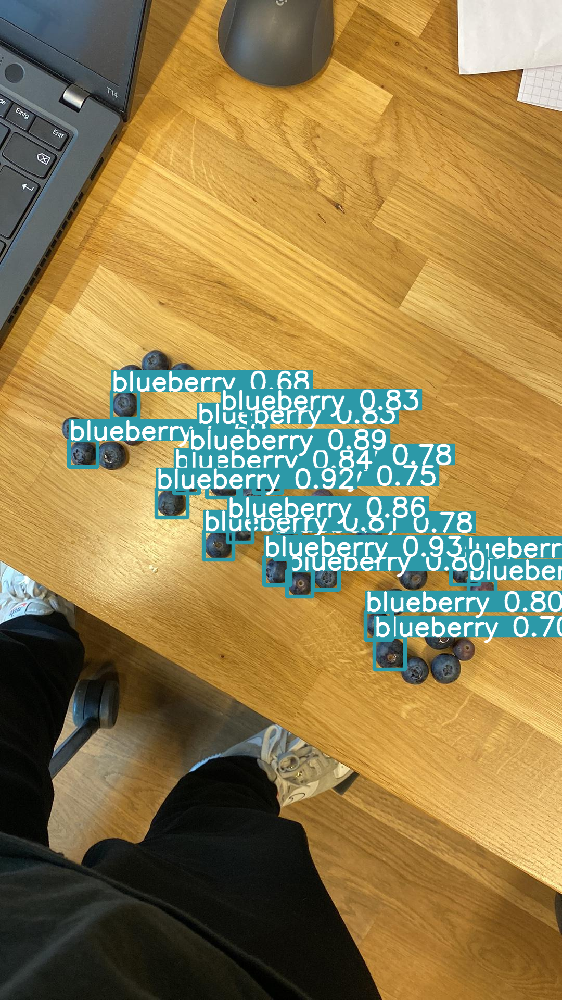

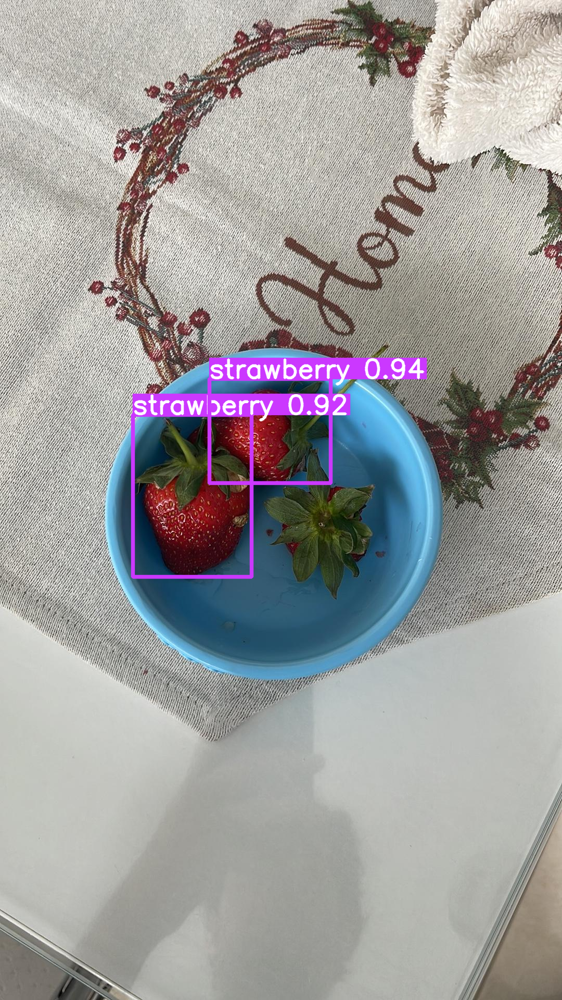

In [9]:
# Show images in this notebook 
from IPython.display import Image, display

for i in range(num_images):
    display(Image(f'Example_Results/{os.path.basename(images[i])}.png', width=200))
